In [15]:
import os
from PIL import Image
import pandas as pd
import seaborn as seaborn
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC


## Vérification nombre d'images de chaque tumeur Training

Ce code permet d'afficher les types de tumeur différentes et le nombre d'images associés à chacune des tumeurs.

In [16]:
liste_tumeur = {}                                                   # On initialise un dictionnaire vide pour stocker chaque tumeurs et le nombre d'images associées

dossier = os.listdir("archive/Training")                            

for k in dossier:                                                   # La boucle qui permet de parcours le dossier pour trouver les différents dossiers relatifs à chaque tumeur
    if k not in liste_tumeur:
        liste_tumeur[k] = 0                                         # On ajoute à la boucle que si elle n'est pas déjà présente dans le dictionnaire

print(f"Liste des différentes tumeurs : {liste_tumeur}") 

for j in liste_tumeur:                                              # On parcourt tout le dictionnaire qui vient d'être rempli 
    dossier_actuel = os.path.join("archive/Training", j)            
    for l in os.listdir(dossier_actuel):
        liste_tumeur[j] += 1                                        # On ajoute 1 à chaque image de chaque tumeurs

print(f"Nombre d'images de chaque tumeur : {liste_tumeur}")

Liste des différentes tumeurs : {'meningioma': 0, 'glioma': 0, 'notumor': 0, 'pituitary': 0}
Nombre d'images de chaque tumeur : {'meningioma': 1400, 'glioma': 1400, 'notumor': 1400, 'pituitary': 1400}


## Graphique nombre d'image de chaque tumeur Training

<Axes: xlabel='Type_Tumeur', ylabel='Count'>

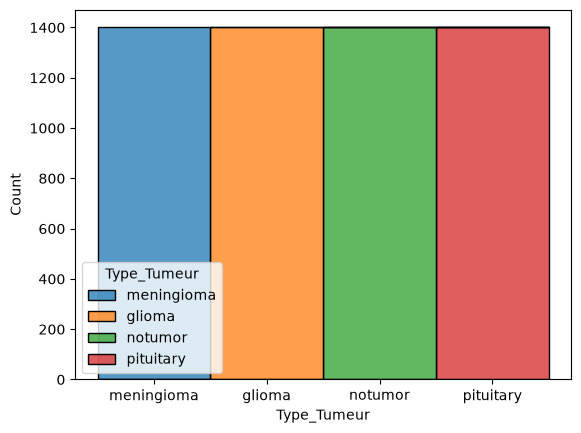

In [17]:
df = pd.DataFrame(list(liste_tumeur.items()), columns=['Type_Tumeur', 'Valeur'])                        # Pour faire un graphique, on transforme le dictionnaire en Dataframe
seaborn.histplot(data=df, x='Type_Tumeur', weights='Valeur', hue='Type_Tumeur', multiple='stack')       # Création du graphique

## Début préprocess (Récupération des infos des images)

In [18]:
df.head()                                                                   # class de df
df.info()                                                                   # infos du nombre d'entrée du df
df.describe()                                                               # Description df (nombre colonne / infos à l'interieur ...)

liste_taille = {}                                                           # On initialise 3 nouveeux dictionnaires pour les 3 vérifications
liste_format = {}
liste_couleur = {}

for j in liste_tumeur.keys():                                               # On va parcourir les différents dossier de tumeurs et regarder les images
    dossier_actuel = os.path.join("archive/Training", j)                   
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("archive/Training", j, l)             
        img = Image.open(fichier_actuel)
        if img.size not in liste_taille.keys():                             # Ajout des différentes dimensions des images
            liste_taille[img.size] = 1
        else:
            liste_taille[img.size] += 1
        if img.format not in liste_format.keys():                           # Ajout de différent format de compression d'image (PNG, JPEG ...)
            liste_format[img.format] = 1
        else:
            liste_format[img.format] += 1 
        if img.mode not in liste_couleur:                                   # Ajout des différent mode de colorimétrie des images (J, RGB, RGBA ...)
            liste_couleur[img.mode] = 1
        else:
            liste_couleur[img.mode] += 1

taille_max = max(liste_taille, key=liste_taille.get)                        # Dimensions les plus présentes
format_max = max(liste_format, key=liste_format.get)                        # Format le plus présent
couleur_max = max(liste_couleur, key=liste_couleur.get)                     # Couleur la plus présente
print("Type de dimensions : ", liste_taille)
print("Type de formats : ", liste_format)
print("Type de couleurs : ", liste_couleur)
print("Dimensions les plus présentes :", str(taille_max) + ". Nombre d'images avec ces dimensions :", liste_taille[taille_max])
print("Format le plus présent :", format_max + ". Nombre d'images avec ce format :", liste_format[format_max])
print("Couleur la plus présente :", couleur_max + ". Nombre d'images avec ce mode de colorimétrie :", liste_couleur[couleur_max])

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Type_Tumeur  4 non-null      str  
 1   Valeur       4 non-null      int64
dtypes: int64(1), str(1)
memory usage: 196.0 bytes
Type de dimensions :  {(512, 512): 4012, (204, 249): 1, (225, 225): 253, (315, 315): 1, (180, 218): 1, (330, 355): 1, (216, 216): 1, (239, 248): 1, (256, 256): 22, (300, 412): 1, (416, 395): 1, (630, 423): 1, (552, 527): 1, (528, 581): 1, (226, 212): 1, (306, 365): 1, (507, 605): 1, (262, 308): 1, (402, 396): 1, (239, 224): 1, (554, 554): 2, (503, 369): 1, (208, 243): 1, (238, 212): 1, (323, 342): 1, (472, 546): 1, (215, 220): 1, (442, 442): 38, (455, 500): 3, (230, 241): 1, (206, 249): 1, (229, 223): 1, (312, 401): 1, (825, 993): 1, (273, 326): 1, (351, 398): 1, (200, 252): 29, (305, 337): 1, (213, 237): 2, (497, 320): 1, (214, 216): 1, (226, 214): 1, (215, 234): 19, (1149, 1019): 1, (300, 

## Première conclusion

Tout d'abord, à la base, on à bien vérifier qu'il y a bien le <b>même nombre d'images</b> pour CHAQUE tumeur, et pour les images SANS tumeurs.

On peut le remarquer via les <b>première vérification</b> ainsi que le <u>graphique</u>. Nous avons en tout, <u>5600 images</u>, réparties en <b>4 catégories</b>, ce qui fait 1400 images par catégorie.

Ensuite, nous avons vérifier les <u>différents éléments</u> de chaques images. Comme leurs <b>dimensions</b>, leurs <b>formats</b> et leurs <b>colorimétries.</b>

On a pu voir que sur les <u>5600 images</u>, 4012 était en (512, 512) ce qui va très certainement devenir nos dimensions par défaut. <b>Cependant</b> il faudra faire attention, car certaines images ne sont pas des carrés. Signifiant qu'une conversion sans vérification pourrait applatir ou couper l'image. 

Ensuite, il y en a 5596 en <b>JPEG</b> et 4 en format <b>PNG</b>, bien que noté comme JPEG. Malgré que ces deux formats de compressions soient différents, nous ne trouvons pas cela dérangeant et <u>décidons de ne pas toucher à ces quatres images</u>. Les enlever serai complément contre-productif étant donné qu'elles reste exploitables comme les autres, et peuvent être comparées entre-elles sans difficultés.

Et enfin, leurs colorimétrie. Le plus courant est le <b>RGB</b> avec 3238 images, cependant, malgré qu'elle soit noté comme en <b>RGB</b>, un IRM n'utilise que des nuances de gris, signifiant que la transformation de toutes les images en mode <b>L (Lab / ou CIELLaB)</b> c'est à dire avec des nuances de gris sur une échelle de 0 à 100. 

Pour notre première étape de normalisation, nous décidons donc : 

- <u>De passer toutes les images en noir et blanc.
- De passer toutes les images en dimensions (512, 512)
- De laisser les images avec leurs modes car 99.9% sont en JPEG</u>

## Premier Preprocess

In [19]:
X_train = []
y_train = []

# Définition des chemins pour éviter les erreurs de frappe
chemin_source = "archive/Training"
chemin_cible = "Dataset_clean/Training"

for j in liste_tumeur.keys():
    dossier_actuel = os.path.join(chemin_source, j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join(chemin_source, j, l)
        Dossier_cible = os.path.join(chemin_cible, j)
        
        img = Image.open(fichier_actuel)
        
        # Conversion en niveaux de gris si nécessaire
        if img.mode not in ("L", "l"):
            img = img.convert('L')

        # Redimensionnement et padding pour arriver à 512x512
        if img.size != (128, 128):
            ratio = 128 / max(img.size)
            nouvelle_taille = (
                int(img.size[0] * ratio),
                int(img.size[1] * ratio)
            )
            img = img.resize(nouvelle_taille)

            nouvelle_img = Image.new("L", (128, 128))
            x = (128 - img.size[0]) // 2
            y = (128 - img.size[1]) // 2
            nouvelle_img.paste(img, (x, y))
            img = nouvelle_img

        # Sauvegarde de l'image nettoyée
        os.makedirs(Dossier_cible, exist_ok=True)
        img.save(os.path.join(Dossier_cible, l))
        
        # Préparation des données pour le modèle
        img_array = np.asarray(img, dtype=np.float16) / 255.0
        img_array = img_array.flatten()

        X_train.append(img_array)
        y_train.append(j)

## Vérification formats images

In [20]:
for j in liste_tumeur.keys():                                               # Vérification que toutes les images sont dans les mêmes formats (dimensions, colorimétrie)
    dossier_actuel = os.path.join("Dataset_clean/Training", j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("Dataset_clean/Training", j, l)
        img = Image.open(fichier_actuel)
        print 
        if img.size != (128, 128):
            print("MAUVAISES DIMENSIONS DETECTÉES")

## Vérification des doublons.

In [21]:
# for j in liste_tumeur.keys():
#     dossier_actuel = os.path.join("Dataset/Training", j)
#     fichiers = os.listdir(dossier_actuel)

#     for i in range(len(fichiers)):
#         for k in range(i + 1, len(fichiers)):
#             image_actuelle = os.path.join(dossier_actuel, fichiers[i])
#             image_suivante = os.path.join(dossier_actuel, fichiers[k])

#             img1 = Image.open(image_actuelle)
#             img2 = Image.open(image_suivante)
#     print("yeah")

In [22]:
X = np.array(X_train)
y = np.array(y_train)

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (5600, 16384)
Dimensions de y : (5600,)


In [23]:
X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train :", X_train_knn.shape)
print("X_test :", X_test_knn.shape)

X_train : (4480, 16384)
X_test : (1120, 16384)


In [24]:

meilleur = 0.0
meilleur_chiffre = 0
for k in range(1, 8, 2):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train_knn)

    y_pred = knn.predict(X_test_knn)

    accuracy = accuracy_score(y_test_knn, y_pred)
    if accuracy > meilleur:
        meilleur = accuracy
        meilleur_chiffre = k
    print(meilleur, meilleur_chiffre)
print(f"Meilleur résultat du KNN via n_neighbors = {meilleur_chiffre} :", meilleur)

0.90625 1
0.90625 1
0.90625 1
0.90625 1
Meilleur résultat du KNN via n_neighbors = 1 : 0.90625


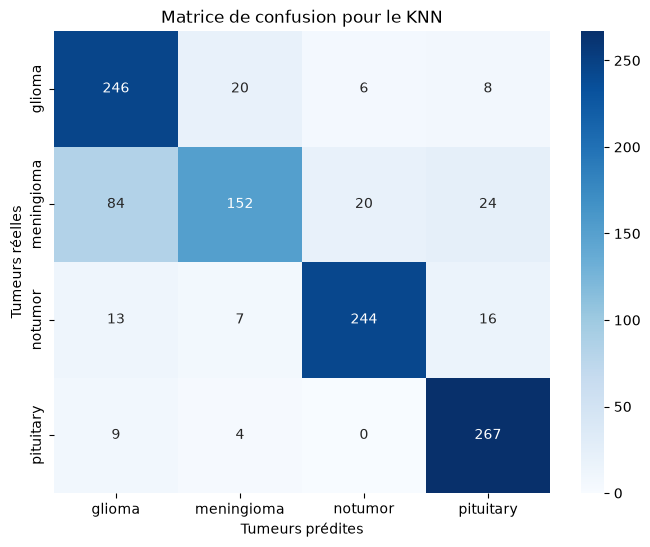

In [25]:

cm = confusion_matrix(y_test_knn, y_pred)

plt.figure(figsize=(8, 6))

seaborn.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=knn.classes_, yticklabels=knn.classes_)

plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion pour le KNN")

plt.show()

In [26]:
randomforest = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
randomforest.fit(X_train_knn, y_train_knn)

y_pred = randomforest.predict(X_test_knn)

accuracy = accuracy_score(y_test_knn, y_pred)
print("Résultat du RandomForestClassifier :", accuracy)

Résultat du RandomForestClassifier : 0.9089285714285714


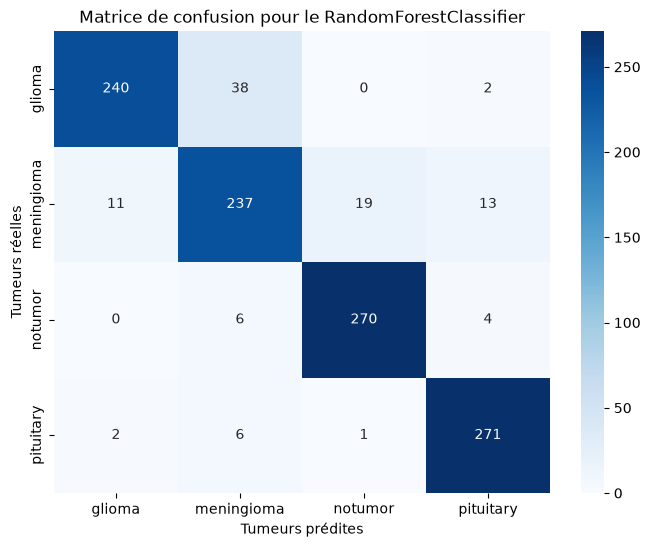

In [27]:
cm = confusion_matrix(y_test_knn, y_pred)

plt.figure(figsize=(8, 6))

seaborn.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=randomforest.classes_, yticklabels=randomforest.classes_)

plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion pour le RandomForestClassifier")

plt.show()

### SVM Modele


Précision du SVM : 0.8562


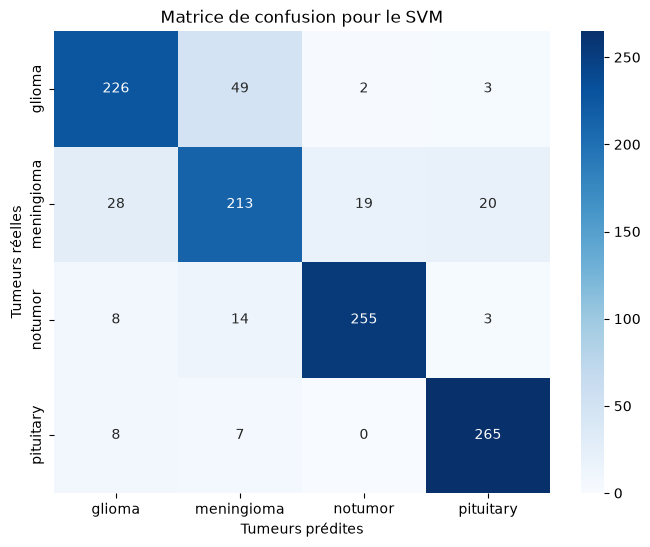

In [ ]:

modele_svm = SVC(kernel="rbf", random_state=42)

modele_svm.fit(X_train_knn, y_train_knn)
predictions = modele_svm.predict(X_test_knn)
precision = accuracy_score(y_test_knn, predictions)

print(f"Précision du SVM : {precision:.4f}")
matrice_confusion = confusion_matrix(y_test_knn, predictions)

plt.figure(figsize=(8, 6))
seaborn.heatmap(matrice_confusion, annot=True, fmt="d", cmap="Blues", xticklabels=modele_svm.classes_, yticklabels=modele_svm.classes_)
plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion - SVM")
plt.show()


Précision de la régression logistique : 0.8304


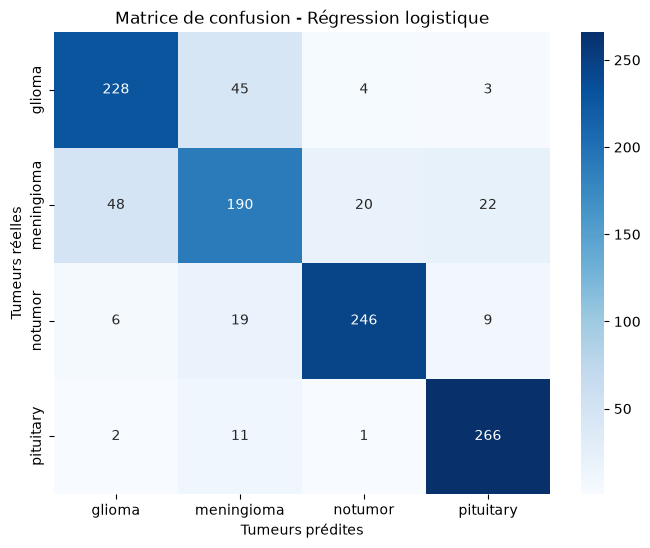

In [31]:
from sklearn.linear_model import LogisticRegression

modele_logreg = LogisticRegression(max_iter=1000, random_state=42)
modele_logreg.fit(X_train_knn, y_train_knn)
predictions = modele_logreg.predict(X_test_knn)
precision = accuracy_score(y_test_knn, predictions)

print(f"Précision de la régression logistique : {precision:.4f}")
matrice_confusion = confusion_matrix(y_test_knn, predictions)

plt.figure(figsize=(8, 6))
seaborn.heatmap(matrice_confusion, annot=True, fmt="d", cmap="Blues", xticklabels=modele_logreg.classes_, yticklabels=modele_logreg.classes_)

plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion - Régression logistique")
plt.show()


### Comparaison des modèles

Maintenant que les quatre modèles ont été entraînés, on peut comparer leurs performances sur les mêmes données de test. Cela permet de voir lequel obtient les meilleurs résultats sur notre jeu de données.

Comparaison des modèles
Accuracy : 0.8116
              precision    recall  f1-score   support

      glioma       0.70      0.88      0.78       280
  meningioma       0.83      0.54      0.66       280
     notumor       0.90      0.87      0.89       280
   pituitary       0.85      0.95      0.90       280

    accuracy                           0.81      1120
   macro avg       0.82      0.81      0.80      1120
weighted avg       0.82      0.81      0.80      1120

Accuracy : 0.9089
              precision    recall  f1-score   support

      glioma       0.95      0.86      0.90       280
  meningioma       0.83      0.85      0.84       280
     notumor       0.93      0.96      0.95       280
   pituitary       0.93      0.97      0.95       280

    accuracy                           0.91      1120
   macro avg       0.91      0.91      0.91      1120
weighted avg       0.91      0.91      0.91      1120

Accuracy : 0.8562
              precision    recall  f1-score   suppor

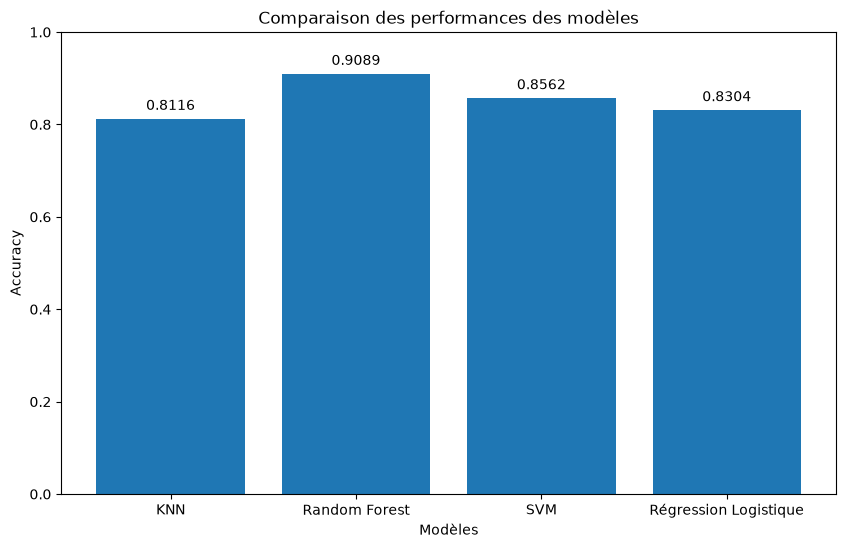

Resultats de la comparaison
Le modèle avec la plus grande accuracy dans ce test est : Random Forest (0.9089)


In [30]:
from sklearn.metrics import classification_report

modeles = {"KNN": knn, "Random Forest": randomforest, "SVM": svm_model, "Régression Logistique": logreg_model}
resultats = {}

print("Comparaison des modèles")

for nom, modele in modeles.items():
    predictions = modele.predict(X_test_knn)
    accuracy = accuracy_score(y_test_knn, predictions)
    resultats[nom] = accuracy
    print(f"Accuracy : {accuracy:.4f}")
    print(classification_report(y_test_knn, predictions))


# Matrice de confusion pour chaque modèle
print("Performance des modèles :")

for nom, accuracy in resultats.items():
    print(f"{nom:<25} : {accuracy:.4f}")


# Comparaison des modèles
plt.figure(figsize=(10, 6))
plt.bar(resultats.keys(), resultats.values())

plt.xlabel("Modèles")
plt.ylabel("Accuracy")
plt.title("Comparaison des performances des modèles")
plt.ylim(0, 1)

# Affichage de la valeur au-dessus de chaque barre
for i, (nom, accuracy) in enumerate(resultats.items()):
    plt.text(i, accuracy + 0.02, f"{accuracy:.4f}", ha="center")
plt.show()


# modèle avec + d'accuracy
meilleur_modele = max(resultats, key=resultats.get)

print("Resultats de la comparaison")
print(f"Le modèle avec la plus grande accuracy dans ce test est : "f"{meilleur_modele} ({resultats[meilleur_modele]:.4f})")
